# RNN
I based this on Deev's edits and integrated it into our project structure.
TODO:
1. verify that this feeds into the classifier or if anything needs to be changed in terms of how the weights and model architecture are read.
2. tune 'em hyperparamters

In [8]:
# imports
import math
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from protgen.data import IGNORE_INDEX
from protgen.models.rnn import RNNEncoder, sample
from utils import load_data

DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [9]:
# load data
data_train, train_loader, X_train, y_train = load_data("../data", "train", "generative")
data_val, val_loader, X_val, y_val = load_data("../data", "val", "generative")

# train data, task: generative
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020, 129])
# val data, task: generative
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001, 129])


In [10]:
# set up LSTM model with Aaam optimiser
SEED = 42
num_epochs = 50
lr = 1e-3
hidden = 256

torch.manual_seed(SEED)
model = RNNEncoder(vocab_size=data_train.vocab_size, emb_dim=64, hidden=hidden, num_layers=2).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
print(model)

RNNEncoder(
  (embed): Embedding(23, 64, padding_idx=0)
  (embed_drop): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (out_drop): Dropout(p=0.2, inplace=False)
  (l_out): Linear(in_features=256, out_features=23, bias=False)
)


In [11]:
# training
# ensure that loss counts only residues and the EOS

# negative log-likelihood (loss)
def nll(x, x_shifted):
    logits, _ = model(x.to(DEVICE))
    return F.cross_entropy(logits.reshape(-1, data_train.vocab_size),
                           x_shifted.reshape(-1).to(DEVICE), ignore_index=IGNORE_INDEX)

training_loss, validation_loss = [], []

for epoch in range(num_epochs):
    epoch_training_loss, epoch_validation_loss = 0.0, 0.0

    # no updating weights
    # that means printed val loss will belong to previous epoch (epoch 0 --> untrained model)
    model.eval()
    with torch.no_grad():
        for x, x_shifted, _, _ in val_loader:
            epoch_validation_loss += nll(x, x_shifted).item() * len(x)

    # now update weights
    model.train()
    for x, x_shifted, _, _ in train_loader:
        loss = nll(x, x_shifted)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_training_loss += loss.item() * len(x)

    # output loss stats and if the model is random guessing (perplexity)
    training_loss.append(epoch_training_loss / len(data_train))
    validation_loss.append(epoch_validation_loss / len(data_val))
    print(f"Epoch {epoch}, training loss: {training_loss[-1]:.4f}, "
          f"validation loss: {validation_loss[-1]:.4f} "
          f"(perplexity {math.exp(validation_loss[-1]):.2f})")

Epoch 0, training loss: 2.0642, validation loss: 3.2508 (perplexity 25.81)
Epoch 1, training loss: 1.5894, validation loss: 1.7201 (perplexity 5.59)
Epoch 2, training loss: 1.4575, validation loss: 1.5872 (perplexity 4.89)
Epoch 3, training loss: 1.3805, validation loss: 1.5263 (perplexity 4.60)
Epoch 4, training loss: 1.3297, validation loss: 1.4987 (perplexity 4.48)
Epoch 5, training loss: 1.2893, validation loss: 1.4797 (perplexity 4.39)
Epoch 6, training loss: 1.2557, validation loss: 1.4543 (perplexity 4.28)
Epoch 7, training loss: 1.2294, validation loss: 1.4482 (perplexity 4.26)
Epoch 8, training loss: 1.2062, validation loss: 1.4352 (perplexity 4.20)
Epoch 9, training loss: 1.1868, validation loss: 1.4284 (perplexity 4.17)
Epoch 10, training loss: 1.1695, validation loss: 1.4212 (perplexity 4.14)
Epoch 11, training loss: 1.1536, validation loss: 1.4090 (perplexity 4.09)
Epoch 12, training loss: 1.1408, validation loss: 1.3969 (perplexity 4.04)
Epoch 13, training loss: 1.1261, v

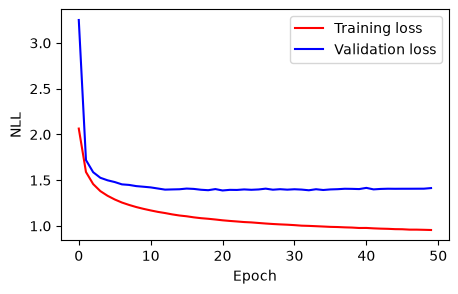

In [12]:
# plot loss curve
epoch = range(len(training_loss))
plt.figure(figsize=(5, 3))
plt.plot(epoch, training_loss, 'r', label='Training loss')
plt.plot(epoch, validation_loss, 'b', label='Validation loss')
plt.legend()
plt.xlabel('Epoch'), plt.ylabel('NLL')
plt.show()

In [13]:
# save config and weights for classifier guidance to use
torch.save({"config": model.config,
            "state_dict": model.state_dict(),
            "val_nll": validation_loss[-1],
            "epochs": num_epochs,
            "seed": SEED}, "../results/rnn.pt")

In [14]:
# generate a few proteins as baseline and save in results
# we can use this to see if classifier guidance helps
torch.manual_seed(SEED)
seqs = sample(model, n=500, temperature=1.0)
pd.DataFrame({"sequence": seqs}).to_csv("../results/sequences/generated_sequences_rnn_unguided.csv", index=False)

lengths = pd.Series([len(s) for s in seqs])
print(lengths.describe()[["min", "mean", "max"]].round(1).to_dict())
print("one example:\n",seqs[0])

{'min': 78.0, 'mean': 94.2, 'max': 127.0}
one example:
 MSHVLIPKSYFIAQQDPQLFRSLNRLTKMNKSEKIRQYIEVKIARTYERSVVIQNQYRDFIAEMSTNHEVTLPPGVKLWAVSQKASTGRNPMTGLTLRIEPRRVVKFKPGNFILGAARDKV
